In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

Following the rational of Turrel's chapter 3.3, we arrive at the following dynamic matrix:

$$
\begin{pmatrix}
k_1 + k_2 - \omega^2 m_1
&
-\big(k_1 e^{i \frac{qd}{2}} + k_2 e^{-i \frac{qd}{2}}\big)
\\[6pt]
-\big(k_1 e^{-i \frac{qd}{2}} + k_2 e^{i \frac{qd}{2}}\big)
&
k_1 + k_2 - \omega^2 m_2
\end{pmatrix}
$$

Solving for $\omega^2$, the determinant simplifies to

$$
\omega_{\pm}^2(q)
=
\frac{
(m_1 + m_2)(k_1 + k_2)
\;\pm\;
\sqrt{
[(m_1 + m_2)(k_1 + k_2)]^2 - 16 m_1 m_2 k_1 k_2 \sin^2(\frac{qd}{2})
}
}{
2 m_1 m_2
}
$$

where q = 2 $\pi$ k and k = $\frac{1}{d}$
 
To simplify the code to compute the branches, we can assume

$$
A = (m_1 + m_2)(k_1 + k_2)
$$

$$
B = [(m_1 + m_2)(k_1 + k_2)]^2 - 16 m_1 m_2 k_1 k_2 \sin^2(\frac{qd}{2})

$$

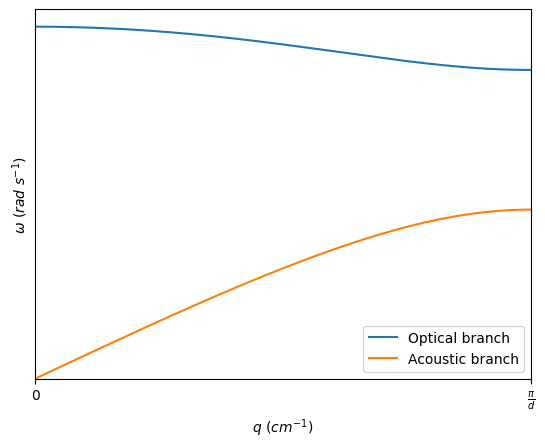

In [8]:
# parameters
k1 = 1
k2 = 1
m1 = 150
m2 = 500
d = 1

# q values (first half of the Brillouin zone)
q = np.linspace(0, np.pi/(d), 500)

# omega^2 branches (with previously mentioned simplification)
A = (m1 + m2) * (k1 + k2)
B = ((m1 + m2) * (k1 + k2))**2 - 16 * m1 * m2 * k1 * k2 * np.sin(q*d/2)**2

plus_sol = (A + np.sqrt(B)) / (2* m1 * m2)
minus_sol = (A - np.sqrt(B)) / (2* m1 * m2)

w_plus = np.sqrt(plus_sol)
w_minus = np.sqrt(minus_sol)

"""
Note: First Brillouin zone at k = [0, 1/2d], and q = 2 pi k
"""
plt.figure()
plt.plot(q, w_plus, label='Optical branch')
plt.plot(q, w_minus, label='Acoustic branch')

# Set up X-axis
plt.xlabel(r'$q \ (cm^{-1})$')
plt.xlim(0, np.pi/d)

# Show ONLY the numerical values at the center and edge
plt.xticks([0, np.pi/d], ['0', r'$\frac{\pi}{d}$'])

# Set up Y-axis
plt.ylabel(r'$\omega \ (rad \ s^{-1})$')
plt.ylim(0)

# Completely remove both tick marks and labels from the Y-axis (omega)
plt.yticks([])

plt.legend()
plt.show()